# Recommendation Systems Assignment: Collaborative Filtering

### CSCI 6517 Recommender System

### Getting MovieLens data

* Download the movielens 100k dataset from this link: [ml-100k.zip](http://files.grouplens.org/datasets/movielens/ml-100k.zip)

* Upload ml-100k.zip

* Extract using the following cell:

### Imports

In [1]:
# import required libraries
import os
import os.path
import numpy as np
import pandas as pd
from math import sqrt
from heapq import nlargest
from tqdm import trange
from tqdm import tqdm
from scipy import stats
from sklearn.metrics.pairwise import pairwise_distances
from sklearn.metrics import mean_squared_error

## Support functions and variables

In [2]:
#!unzip ml-100k.zip -d .

In [3]:
MOVIELENS_DIR = "ml-100k"

In [4]:
import os

print(os.listdir(MOVIELENS_DIR))

['u.item', 'u3.test', 'u1.base', 'u.info', 'u2.test', 'u5.test', 'u.genre', 'ub.test', 'ua.base', 'u.data', 'README', 'u4.test', 'u5.base', 'ub.base', 'ua.test', 'u4.base', 'u.user', 'allbut.pl', 'u3.base', 'u1.test', 'mku.sh', 'u2.base', 'u.occupation']


In [5]:
def getData(folder_path, file_name):
    fields = ['userID', 'itemID', 'rating', 'timestamp']
    data = pd.read_csv(os.path.join(folder_path, file_name), sep='\t', names=fields)
    return data 

In [6]:
rating_df = getData(MOVIELENS_DIR, 'u.data')

In [7]:
num_users = len(rating_df.userID.unique())
num_items = len(rating_df.itemID.unique())
print("Number of users:", num_users)
print("Number of items:", num_items)

Number of users: 943
Number of items: 1682


## Q1

### (a)

In [8]:
def dataPreprocessor(rating_df, num_users, num_items):
    """
        INPUT: 
            data: pandas DataFrame. columns=['userID', 'itemID', 'rating' ...]
            num_row: int. number of users
            num_col: int. number of items
            
        OUTPUT:
            matrix: 2D numpy array. 
            
        NOTE 1: see where something very similar is done in the lab in function 'buildUserItemMatrix'    
            
        NOTE 2: data can have more columns, but your function should ignore 
              additional columns.
    """
    ########### your code goes here ###########
    matrix = np.zeros((num_users, num_items), dtype=np.int8) # initialize the user-item matrix with zeros
    matrix[rating_df.userID.values - 1, rating_df.itemID.values - 1] = rating_df.rating.values # fill the user-item matrix with ratings from the DataFrame
    ###########         end         ###########
    return matrix

In [9]:
dataPreprocessor(rating_df, num_users, num_items)

array([[5, 3, 4, ..., 0, 0, 0],
       [4, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [5, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 5, 0, ..., 0, 0, 0]], shape=(943, 1682), dtype=int8)

### (b)

In [81]:
class BaseLineRecSys(object):
    def __init__(self, method, processor=dataPreprocessor):
        """
            method: string. From ['popularity','useraverage']
            processor: function name. dataPreprocessor by default
        """
        self.method_name = method
        self.method = self._getMethod(self.method_name)
        self.processor = processor
        self.pred_column_name = self.method_name
        
    def _getMethod(self, method_name):
        """
            Don't change this
        """
        switcher = {
            'popularity': self.popularity,
            'useraverage': self.useraverage,
        }
        
        return switcher[method_name]
    
    @staticmethod
    def useraverage(train_matrix, num_users, num_items):
        """
            INPUT:
                train_matrix: 2D numpy array.
                num_users: int. Number of Users.
                num_items: int. Number of Items.
            OUTPUT:
                predictionMatrix: 2D numpy array.
                
            NOTE: see where something very similar is done in the lab in function 'predictByUserAverage'    
        """
        
        predictionMatrix = np.zeros((num_users, num_items))
        ########### your code goes here ###########
        # Initialize the predicted rating matrix with zeros
        sum_ratings = train_matrix.sum(axis=1) # sum of ratings for each user
        count_ratings = (train_matrix != 0).sum(axis=1) # count of ratings for each user
        count_ratings[count_ratings == 0] = 1 # to avoid division by zero
        user_averages = sum_ratings / count_ratings # average rating for each user
        predictionMatrix = np.tile(user_averages.reshape(-1, 1), (1, num_items)) # fill the predicted rating matrix with user averages

        ###########         end         ###########
        return predictionMatrix
    
    @staticmethod
    def popularity(train_matrix, num_users, num_items):
        """
            INPUT:
                train_matrix: 2D numpy array.
                num_users: int. Number of Users.
                num_items: int. Number of Items.
            OUTPUT:
                predictionMatrix: 2D numpy array.
                
            NOTE: see where something very similar is done in the lab in function 'predictByPopularity'    
        """
        
        predictionMatrix = np.zeros((num_users, num_items))
        ########### your code goes here ###########
        # Initialize the predicted rating matrix with zeros
        liked_mask = (train_matrix >= 4).astype(float) # 1 item wher ratin >= 4, else 0
        rated_mask = (train_matrix != 0).astype(float) # 1 item where rating != 0, else 0
        #counting per item how many users rated it and how many users liked it
        liked_counts = liked_mask.sum(axis=0) # shape (num_items,)
        rated_counts = rated_mask.sum(axis=0) # shape (num_items,)
        # then popularity score per item and avoding division by zero
        item_popularity = np.where(rated_counts > 0, liked_counts / rated_counts, 0)
        ###########         end         ###########
        return predictionMatrix    
    
    def predict_all(self, train_df, num_users, num_items):
        
        train_matrix = self.processor(train_df, num_users, num_items)
        self.__model = self.method(train_matrix, num_users, num_items)
        
    def evaluate_test(self, test_df, copy=False):
        
        if copy:
            prediction = test_df.copy()
        else:
            prediction = test_df
            
        prediction[self.pred_column_name] = np.nan
        
        for (index, 
             userID, 
             itemID) in tqdm(prediction[['userID','itemID']].itertuples()):
            prediction.loc[index, self.pred_column_name] = self.__model[userID-1, itemID-1]

        return prediction
        
    def getModel(self):
        """
            return predicted user-item matrix
        """
        return self.__model
    
    def getPredColName(self):
        """
            return prediction column name
        """
        return self.pred_column_name
    
    def reset(self):
        """
            reuse the instance of the class by removing model
        """
        try:
            self.model = None
        except:
            print("You don not have model..")
            

In [11]:
popularity_recsys = BaseLineRecSys('popularity')

In [12]:
popularity_recsys.predict_all(rating_df, num_users, num_items)

In [13]:
x = popularity_recsys.getModel()

In [14]:
np.all(x<=1)

np.True_

In [15]:
rating_df.head()

,userID,itemID,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [16]:
popularity_recsys.evaluate_test(rating_df,copy=True).head()

100000it [00:03, 31719.49it/s]


,userID,itemID,rating,timestamp,popularity
0,196,242,3,881250949,0.0
1,186,302,3,891717742,0.0
2,22,377,1,878887116,0.0
3,244,51,2,880606923,0.0
4,166,346,1,886397596,0.0


In [17]:
average_user_rating_recsys = BaseLineRecSys('useraverage')

In [18]:
average_user_rating_recsys.predict_all(rating_df, num_users, num_items)

In [19]:
average_user_rating_recsys.getModel()

array([[3.61029412, 3.61029412, 3.61029412, ..., 3.61029412, 3.61029412,
        3.61029412],
       [3.70967742, 3.70967742, 3.70967742, ..., 3.70967742, 3.70967742,
        3.70967742],
       [2.7962963 , 2.7962963 , 2.7962963 , ..., 2.7962963 , 2.7962963 ,
        2.7962963 ],
       ...,
       [4.04545455, 4.04545455, 4.04545455, ..., 4.04545455, 4.04545455,
        4.04545455],
       [4.26582278, 4.26582278, 4.26582278, ..., 4.26582278, 4.26582278,
        4.26582278],
       [3.41071429, 3.41071429, 3.41071429, ..., 3.41071429, 3.41071429,
        3.41071429]], shape=(943, 1682))

In [20]:
average_user_rating_recsys.evaluate_test(rating_df,copy=True).head()

100000it [00:03, 30644.84it/s]


,userID,itemID,rating,timestamp,useraverage
0,196,242,3,881250949,3.615385
1,186,302,3,891717742,3.413043
2,22,377,1,878887116,3.351562
3,244,51,2,880606923,3.651261
4,166,346,1,886397596,3.550000


## Q2

### (a)

In [80]:
class SimBasedRecSys(object):

    def __init__(self, base, method, processor=dataPreprocessor):
        """
            base: string. From ['user', 'item']. User-based Similarity or Item-based
            method: string. From ['cosine', 'euclidean', 'somethingelse']
            processor: function name. dataPreprocessor by default
        """
        self.base = base
        self.method_name = method
        self.method = self._getMethod(self.method_name)
        self.processor = processor
        self.pred_column_name = self.base+'-'+self.method_name
    
    def _getMethod(self, method_name):
        """
            Don't change this
        """
        switcher = {
            'cosine': self.cosine,
            'euclidean': self.euclidean,
            'somethingelse': self.somethingelse,
        }
        
        return switcher[method_name]
    
    @staticmethod
    def cosine(matrix):
        """
            cosine similarity
        """
        similarity_matrix = 1 - pairwise_distances(matrix, metric='cosine')
        return similarity_matrix
    
    @staticmethod
    def euclidean(matrix):
        """
            euclidean similarity
        """
        ########### your code goes here ###########
        distance_matrix = pairwise_distances(matrix, metric='euclidean') # euclidean distance matrix
        similarity_matrix = 1 / (1 + distance_matrix)
        ###########         end         ###########    
        
        return similarity_matrix
    
    @staticmethod
    def somethingelse(matrix):
        """
            manhattan? or super-natural intuition similarity
        """
        ########### your code goes here ###########
        distance_matrix = pairwise_distances(matrix, metric='cityblock')
        similarity_matrix = 1 / (1 + distance_matrix)

        """ 
            - Manhattan distance penalizes each rating dimension equally regardless of magnitude, 
            making it less sensitive to a single extreme rating mismatch than Euclidean, which squares the differences.
            [source](https://medium.com/geekculture/understand-manhattan-vs-euclidean-distance-in-minutes-f10f7a65a90f)
        """
        ###########         end         ###########        
        return similarity_matrix
        
    def predict_all(self, train_df, num_users, num_items):
        """
            INPUT: 
                data: pandas DataFrame. columns=['userID', 'itemID', 'rating'...]
                num_row: scalar. number of users
                num_col: scalar. number of items
            OUTPUT:
                no return... this method assigns the result to self.model
            
            NOTES:
                self.__model should contain predictions for *all* user and items
                (don't worry about predicting for observed (user,item) pairs,
                 since we won't be using these predictions in the evaluation)
                (see code in for an efficient vectorized example)
        """
        train_matrix = self.processor(train_df, num_users, num_items)
        
        if self.base == 'user':
            ########### your code goes here ###########
            sim_matrix = self.method(train_matrix)                 # (num_users, num_users) get similarity between users
            rated_mask = (train_matrix != 0).astype(float)         # (num_users, num_items) create a mask of rated items (1 if rated, 0 if not)
            numerator = sim_matrix @ train_matrix                  # (num_users, num_items) predict ratings by summing over all users' ratings weighted by similarity
            denominator = sim_matrix @ rated_mask                  # (num_users, num_items)  <-- only sum sims of users who rated item i
            denominator[denominator == 0] = 1e-9                   # avoid divide-by-zero / NaN
            self.__model = numerator / denominator
            ###########         end         ###########
            
        elif self.base == 'item':
            ########### your code goes here ###########
            sim_matrix = self.method(train_matrix.T)               # (num_items, num_items)
            rated_mask = (train_matrix != 0).astype(float)         # (num_users, num_items)
            numerator = train_matrix @ sim_matrix                  # (num_users, num_items)
            denominator = rated_mask @ sim_matrix                  # (num_users, num_items)
            denominator[denominator == 0] = 1e-9
            self.__model = numerator / denominator
            ###########         end         ###########
        else:
            print('No other option available')
        
    def evaluate_test(self, test_df, copy=False):
        """
            INPUT:
                data: pandas DataFrame. columns=['userID', 'itemID', 'rating'...]
            OUTPUT:
                predictions:  pandas DataFrame. 
                              columns=['userID', 'itemID', 'rating', 'base-method'...]
                              
            NOTE: 1. data can have more columns, but your function should ignore 
                  additional columns.
                  2. 'base-method' depends on your 'base' and 'method'. For example,
                  if base == 'user' and method == 'cosine', 
                  then base-method == 'user-cosine'
                  3. your predictions go to 'base-method' column
        """
        if copy:
            prediction = test_df.copy()
        else:
            prediction = test_df
        prediction[self.pred_column_name] = np.nan
        
        for (index, 
             userID, 
             itemID) in tqdm(prediction[['userID','itemID']].itertuples()):
            prediction.loc[index, self.pred_column_name] = self.__model[userID-1, itemID-1]
    
        return prediction
    
    def getModel(self):
        """
            return predicted user-item matrix
        """
        return self.__model
    
    def getPredColName(self):
        """
            return prediction column name
        """
        return self.pred_column_name
    
    def reset(self):
        """
            reuse the instance of the class by removing model
        """
        try:
            self.model = None
        except:
            print("You do not have model..")

In [32]:
# Examples of how to call similarity functions.
I = np.eye(3)
SimBasedRecSys.cosine(I)

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

In [33]:
SimBasedRecSys.euclidean(I)

array([[1.        , 0.41421356, 0.41421356],
       [0.41421356, 1.        , 0.41421356],
       [0.41421356, 0.41421356, 1.        ]])

In [34]:
SimBasedRecSys.somethingelse(I)

array([[1.        , 0.33333333, 0.33333333],
       [0.33333333, 1.        , 0.33333333],
       [0.33333333, 0.33333333, 1.        ]])

### (b)

In [ ]:
""" 
* Manhattan distance penalizes each rating dimension equally regardless of magnitude, 
making it less sensitive to a single extreme rating mismatch than Euclidean, which squares the differences.
[source](https://medium.com/geekculture/understand-manhattan-vs-euclidean-distance-in-minutes-f10f7a65a90f)
"""

## Q3

### (a)

In [35]:
user_cosine_recsys = SimBasedRecSys('user','cosine')

In [36]:
user_cosine_recsys.predict_all(rating_df, num_users, num_items)

In [37]:
user_cosine_recsys.getModel()

array([[3.89911175, 3.19022667, 3.0261129 , ..., 2.        , 3.        ,
        3.        ],
       [3.84034456, 3.17139889, 2.92626717, ..., 2.        , 3.        ,
        3.        ],
       [3.87104065, 3.12823798, 3.03250708, ..., 2.        , 3.        ,
        3.        ],
       ...,
       [3.90754645, 3.20227238, 3.05776201, ..., 2.        , 3.        ,
        3.        ],
       [3.91100649, 3.21591021, 2.98854017, ..., 2.        , 3.        ,
        3.        ],
       [3.91593122, 3.24268207, 3.08255897, ..., 0.        , 3.        ,
        3.        ]], shape=(943, 1682))

In [38]:
rating_df.head()

,userID,itemID,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [39]:
user_cosine_recsys.evaluate_test(rating_df,copy=True).head()

100000it [00:03, 32963.24it/s]


,userID,itemID,rating,timestamp,user-cosine
0,196,242,3,881250949,4.025213
1,186,302,3,891717742,4.142828
2,22,377,1,878887116,1.922080
3,244,51,2,880606923,3.431884
4,166,346,1,886397596,3.424963


### (b)

In [58]:
class CrossValidation(object):
    def __init__(self, metric, data_path=MOVIELENS_DIR):
        """
            INPUT:
                metric: string. from['RMSE','P@K','R@K']
        """
        self.folds = self._getData(MOVIELENS_DIR)
        self.metric_name = metric
        self.metric = self._getMetric(self.metric_name)
        
    def _getMetric(self, metric_name):
        """
            Don't change this
        """
        switcher = {
            'RMSE': self.rmse,
            'P@K': self.patk,
            'R@K': self.ratk,
        }
        
        return switcher[metric_name]
    
    @staticmethod
    def rmse(data, k, num_users, num_items, pred, true='rating'):
        """
            data: pandas DataFrame. 
            pred: string. Column name that corresponding to the prediction
            true: string. Column name that corresponding to the true rating
        """
        return sqrt(mean_squared_error(data[pred], data[true]))
    
    # Precision at k
    def patk(self, data, k, num_users, num_items, pred, true='rating'):
        """
            data: pandas DataFrame. 
            k: top-k items retrieved
            pred: string. Column name that corresponding to the prediction
            true: string. Column name that corresponding to the true rating
        """
        prediction = self.getMatrix(data, num_users, num_items, pred)
        testSet =  self.getMatrix(data, num_users, num_items, true)
    
        # Initialize sum and count vars for average calculation
        sumPrecisions = 0
        countPrecisions = 0

        # Define function for converting 1-5 rating to 0/1 (like / don't like)
        vf = np.vectorize(lambda x: 1 if x >= 4 else 0)

        for userID in range(num_users):
            # Pick top K based on predicted rating
            userVector = prediction[userID,:]
            topK = nlargest(k, range(len(userVector)), userVector.take)

            # Convert test set ratings to like / don't like
            userTestVector = vf(testSet[userID,:]).nonzero()[0]

            # Calculate precision
            precision = float(len([item for item in topK if item in userTestVector]))/len(topK)

            # Update sum and count
            sumPrecisions += precision
            countPrecisions += 1

        # Return average P@k
        return float(sumPrecisions)/countPrecisions
    
    # Recall at k
    def ratk(self, data, k, num_users, num_items, pred, true='rating'):
        """
            data: pandas DataFrame. 
            k: top-k items relevant
            pred: string. Column name that corresponding to the prediction
            true: string. Column name that corresponding to the true rating
        """
        prediction = self.getMatrix(data, num_users, num_items, pred)
        testSet =  self.getMatrix(data, num_users, num_items, true)
        # Initialize sum and count vars for average calculation
        sumRecalls = 0
        countRecalls = 0

        # Define function for converting 1-5 rating to 0/1 (like / don't like)
        vf = np.vectorize(lambda x: 1 if x >= 4 else 0)

        for userID in range(num_users):
            # Pick top K based on predicted rating
            userVector = prediction[userID,:]
            topK = nlargest(k, range(len(userVector)), userVector.take)

            # Convert test set ratings to like / don't like
            userTestVector = vf(testSet[userID,:]).nonzero()[0]

            # Ignore user if has no ratings in the test set
            if (len(userTestVector) == 0):
                continue

            # Calculate recall
            recall = float(len([item for item in topK if item in userTestVector]))/len(userTestVector)

            # Update sum and count
            sumRecalls += recall
            countRecalls += 1

        # Return average R@k
        return float(sumRecalls)/countRecalls
    
    @staticmethod
    def getMatrix(rating_df, num_users, num_items, column_name):
        matrix = np.zeros((num_users, num_items))
    
        for (index, userID, itemID, value) in rating_df[['userID','itemID', column_name]].itertuples():
            matrix[userID-1, itemID-1] = value
            
        return matrix
    
    @staticmethod
    def _getData(data_path):
        """
            Don't change this function
        """
        folds = []
        data_types = ['u{0}.base','u{0}.test']
        for i in range(1,6):
            train_set = getData(data_path, data_types[0].format(i))
            test_set = getData(data_path, data_types[1].format(i))
            folds.append([train_set, test_set])
        return folds
    
    def run(self, algorithms, num_users, num_items, k=1):
        """
            5-fold cross-validation
            algorithms: list. a list of algorithms. 
                        eg: [user_cosine_recsys, item_euclidean_recsys]
        """
        
        scores = {}
        for algorithm in algorithms:
            print('Processing algorithm {0}'.format(algorithm.getPredColName()))
            fold_scores = []
            for fold in self.folds:
                algorithm.reset()
                algorithm.predict_all(fold[0], num_users, num_items)
                prediction = algorithm.evaluate_test(fold[1])
                pred_col = algorithm.getPredColName()
                fold_scores.append(self.metric(prediction, k, num_users, num_items, pred_col))
                
            mean = np.mean(fold_scores)
            ci_low, ci_high = stats.t.interval(0.95, len(fold_scores)-1, loc=mean, scale=stats.sem(fold_scores))
            scores[algorithm.getPredColName()] = [fold_scores, mean, ci_low, ci_high]
            
        results = scores    
    
        return results
            

In [59]:
# How to use CrossValidation Class?

In [60]:
# 1. gather your algorithms in previous steps.
algorithm_instances = [popularity_recsys, 
                       average_user_rating_recsys, 
                       user_cosine_recsys]

In [61]:
# 2. Instantiate a CrossValidation instance and assign the measurement that you want to use
# RMSE, P@K, R@K
# Precision at K in this example
cv_patk = CrossValidation('P@K')

In [62]:
# 3. Run CV by giving:
#    1> algorithms just gathered
#    2> number of users in the full dataset
#    3> number of items in the full dataset
#    4> precision or recall at K need a K value, so k=5 means precision at 5 in this example
# Results include independent results from 5 folds, their mean, and confidence interval.
cv_patk.run(algorithm_instances, num_users, num_items,k=5)

/var/folders/j5/vmwvb3vj1k18lnx4rzmv03pw0000gn/T/ipykernel_8996/3235414772.py:70: RuntimeWarning: invalid value encountered in divide
  item_popularity = np.where(rated_counts > 0, liked_counts / rated_counts, 0)


Processing algorithm popularity


20000it [00:00, 30045.60it/s]
/var/folders/j5/vmwvb3vj1k18lnx4rzmv03pw0000gn/T/ipykernel_8996/3235414772.py:70: RuntimeWarning: invalid value encountered in divide
  item_popularity = np.where(rated_counts > 0, liked_counts / rated_counts, 0)
20000it [00:00, 31726.19it/s]
/var/folders/j5/vmwvb3vj1k18lnx4rzmv03pw0000gn/T/ipykernel_8996/3235414772.py:70: RuntimeWarning: invalid value encountered in divide
  item_popularity = np.where(rated_counts > 0, liked_counts / rated_counts, 0)
20000it [00:00, 25814.64it/s]
/var/folders/j5/vmwvb3vj1k18lnx4rzmv03pw0000gn/T/ipykernel_8996/3235414772.py:70: RuntimeWarning: invalid value encountered in divide
  item_popularity = np.where(rated_counts > 0, liked_counts / rated_counts, 0)
20000it [00:00, 31293.47it/s]
/var/folders/j5/vmwvb3vj1k18lnx4rzmv03pw0000gn/T/ipykernel_8996/3235414772.py:70: RuntimeWarning: invalid value encountered in divide
  item_popularity = np.where(rated_counts > 0, liked_counts / rated_counts, 0)
20000it [00:00, 31567.11it/s

Processing algorithm useraverage


20000it [00:00, 29990.27it/s]
20000it [00:00, 31976.81it/s]
20000it [00:00, 29976.20it/s]
20000it [00:00, 32169.60it/s]
20000it [00:00, 31293.28it/s]


Processing algorithm user-cosine


20000it [00:00, 24857.32it/s]
20000it [00:00, 31378.20it/s]
20000it [00:00, 32361.31it/s]
20000it [00:00, 32237.74it/s]
20000it [00:00, 29371.77it/s]


{'popularity': [[0.020148462354188733,
   0.02481442205726401,
   0.02651113467656411,
   0.022269353128313855,
   0.02651113467656411],
  np.float64(0.02405090137857896),
  np.float64(0.02058916285561012),
  np.float64(0.0275126399015478)],
 'useraverage': [[0.30604453870625714,
   0.4305408271474029,
   0.5321314952279973,
   0.5520678685047737,
   0.5474019088016986],
  np.float64(0.4736373276776259),
  np.float64(0.3419993013451062),
  np.float64(0.6052753540101456)],
 'user-cosine': [[0.37179215270413657,
   0.503923647932133,
   0.621633085896077,
   0.6483563096500541,
   0.6335100742311777],
  np.float64(0.5558430540827157),
  np.float64(0.4095984949998374),
  np.float64(0.702087613165594)]}

In [63]:
item_cosine_recsys = SimBasedRecSys('item', 'cosine')

cv_rmse = CrossValidation('RMSE')
results = cv_rmse.run([user_cosine_recsys, item_cosine_recsys], num_users, num_items)

# results 
for name, (folds, mean, ci_low, ci_high) in results.items():
    print(f"{name}: mean={mean:.4f}, 95% Conf.Interval=[{ci_low:.4f}, {ci_high:.4f}]")

print("Avg ratings per user:", rating_df.groupby('userID')['rating'].count().mean())
print("Avg ratings per item:", rating_df.groupby('itemID')['rating'].count().mean())


Processing algorithm user-cosine


20000it [00:00, 29480.03it/s]
20000it [00:00, 32099.74it/s]
20000it [00:00, 31981.13it/s]
20000it [00:00, 31734.86it/s]
20000it [00:00, 31551.11it/s]


Processing algorithm item-cosine


20000it [00:00, 30069.17it/s]
20000it [00:00, 28346.09it/s]
20000it [00:00, 21263.83it/s]
20000it [00:00, 30560.25it/s]
20000it [00:00, 27497.16it/s]

user-cosine: mean=1.0222, 95% Conf.Interval=[1.0140, 1.0304]
item-cosine: mean=1.0201, 95% Conf.Interval=[1.0068, 1.0333]
Avg ratings per user: 106.04453870625663
Avg ratings per item: 59.45303210463734


Item-item CF got a slightly lower RMSE (1.0201 vs 1.0222), but since the confidence intervals overlap, in easy words both methods perform about the same.

In the dataset there are ~106 ratings per user but only ~59 per item, meaning we know more about each user's preferences than each item's audience. This gives user-user similarity an advantage in theory, since comparing users relies on more data points. Yet item-item still matched it, likely because movies naturally group into genres, if two users both liked a movie, they probably share taste in similar movies too, making item comparisons reliable even with fewer ratings.


## Q4

### (a)

In [65]:
# adding extra algorithms to compare (euclidean and manhattan similarity for both user-based and item-based CF)
user_euclidean_recsys = SimBasedRecSys('user', 'euclidean')
item_euclidean_recsys = SimBasedRecSys('item', 'euclidean')
user_somethingelse_recsys = SimBasedRecSys('user', 'somethingelse')
item_somethingelse_recsys = SimBasedRecSys('item', 'somethingelse')
# recommenders to compare
algorithms = [
    popularity_recsys,
    average_user_rating_recsys,
    user_cosine_recsys,
    item_cosine_recsys,
    user_euclidean_recsys,
    item_euclidean_recsys,
    user_somethingelse_recsys,
    item_somethingelse_recsys,
]

# init crosvalidation for rmse, precision at 5, and recall at 5
cv_rmse = CrossValidation('RMSE')
cv_patk = CrossValidation('P@K')
cv_ratk = CrossValidation('R@K')

results_rmse = cv_rmse.run(algorithms, num_users, num_items)
results_patk = cv_patk.run(algorithms, num_users, num_items, k=5)
results_ratk = cv_ratk.run(algorithms, num_users, num_items, k=5)

##printing results as table
rows = []
for name in results_rmse:
    _, rmse_mean, rmse_lo, rmse_hi = results_rmse[name]
    _, patk_mean, patk_lo, patk_hi = results_patk[name]
    _, ratk_mean, ratk_lo, ratk_hi = results_ratk[name]
    rows.append({
        'Algorithm': name,
        'RMSE (mean [95% CI])':  f"{rmse_mean:.4f} [{rmse_lo:.4f}, {rmse_hi:.4f}]",
        'P@5 (mean [95% CI])':   f"{patk_mean:.4f} [{patk_lo:.4f}, {patk_hi:.4f}]",
        'R@5 (mean [95% CI])':   f"{ratk_mean:.4f} [{ratk_lo:.4f}, {ratk_hi:.4f}]",
    })

pd.DataFrame(rows).set_index('Algorithm')


/var/folders/j5/vmwvb3vj1k18lnx4rzmv03pw0000gn/T/ipykernel_8996/3235414772.py:70: RuntimeWarning: invalid value encountered in divide
  item_popularity = np.where(rated_counts > 0, liked_counts / rated_counts, 0)


Processing algorithm popularity


20000it [00:00, 35094.67it/s]
/var/folders/j5/vmwvb3vj1k18lnx4rzmv03pw0000gn/T/ipykernel_8996/3235414772.py:70: RuntimeWarning: invalid value encountered in divide
  item_popularity = np.where(rated_counts > 0, liked_counts / rated_counts, 0)
20000it [00:00, 34883.49it/s]
/var/folders/j5/vmwvb3vj1k18lnx4rzmv03pw0000gn/T/ipykernel_8996/3235414772.py:70: RuntimeWarning: invalid value encountered in divide
  item_popularity = np.where(rated_counts > 0, liked_counts / rated_counts, 0)
20000it [00:00, 33056.60it/s]
/var/folders/j5/vmwvb3vj1k18lnx4rzmv03pw0000gn/T/ipykernel_8996/3235414772.py:70: RuntimeWarning: invalid value encountered in divide
  item_popularity = np.where(rated_counts > 0, liked_counts / rated_counts, 0)
20000it [00:00, 31269.20it/s]
/var/folders/j5/vmwvb3vj1k18lnx4rzmv03pw0000gn/T/ipykernel_8996/3235414772.py:70: RuntimeWarning: invalid value encountered in divide
  item_popularity = np.where(rated_counts > 0, liked_counts / rated_counts, 0)
20000it [00:00, 33540.44it/s

Processing algorithm useraverage


20000it [00:00, 34579.82it/s]
20000it [00:00, 34746.24it/s]
20000it [00:00, 34865.31it/s]
20000it [00:00, 34953.42it/s]
20000it [00:00, 34809.08it/s]


Processing algorithm user-cosine


... (40 outputs left out)

20000it [00:00, 32333.53it/s]
20000it [00:00, 32315.87it/s]
20000it [00:00, 32760.72it/s]
20000it [00:00, 32516.25it/s]
20000it [00:00, 32369.79it/s]


Processing algorithm item-somethingelse


20000it [00:00, 30924.36it/s]
20000it [00:00, 32094.49it/s]
20000it [00:00, 32522.18it/s]
20000it [00:00, 32038.44it/s]
20000it [00:00, 31004.49it/s]


,RMSE (mean [95% CI]),P@5 (mean [95% CI]),R@5 (mean [95% CI])
Algorithm,,,
popularity,"3.7050 [3.6886, 3.7214]","0.0241 [0.0206, 0.0275]","0.0109 [0.0086, 0.0133]"
useraverage,"1.0437 [1.0289, 1.0585]","0.4736 [0.3420, 0.6053]","0.4413 [0.3293, 0.5533]"
user-cosine,"1.0222 [1.0140, 1.0304]","0.5558 [0.4096, 0.7021]","0.4863 [0.3694, 0.6031]"
item-cosine,"1.0201 [1.0068, 1.0333]","0.5322 [0.3837, 0.6807]","0.4750 [0.3536, 0.5964]"
user-euclidean,"1.0273 [1.0188, 1.0359]","0.5525 [0.4075, 0.6976]","0.4838 [0.3653, 0.6023]"
item-euclidean,"1.0285 [1.0157, 1.0413]","0.5474 [0.4026, 0.6922]","0.4773 [0.3586, 0.5960]"
user-somethingelse,"1.0272 [1.0186, 1.0359]","0.5522 [0.4067, 0.6977]","0.4838 [0.3658, 0.6019]"
item-somethingelse,"1.0235 [1.0114, 1.0356]","0.5450 [0.4008, 0.6892]","0.4756 [0.3565, 0.5946]"


### (b) Some baselines cannot be evaluated with some metrics? Which ones and why?

 The popularity cannot be meaninfully evaluated with RMSE. It happends basically because its scores are factions (between 0-1) which means the portion of user who liked an items, not ratings on the 1-5 scale. The RMSE of 3.705 confirms this hypothesis, it is like comparing apple with oranges. P@5 and R@5 are fine for popularity since they only need a relative ranking, not absolute values. **useraverage** can be evaluated on all three metrics since it predicts actual rating values.

### (c) What is the best algorithm for each of RMSE, P@k, and R@k? Can you explain why this may be?

RMSE rewards getting the *exact rating value* close; P@k/R@k reward getting the *relative order of liked vs. unliked* items right. Best algorithms per metric:

- RMSE -> **item-cosine** (1.0201): Item-item similarity captures stable co-rating patterns, leading to more accurate rating value predictions.

- P@5/R@5 -> **user-cosine** (0.5558, 0.4863 respectively) : Finding users with similar tastes is better at identifying which items user will like, even if the exact predicted rating is slightly off.

### (d) Does good performance on RMSE imply good performance on ranking metrics and vice versa? Why / why not?

I'd say no, basically because they measure different things: 
- RMSE rewards predicting exact rating (close values)
- P@k / R@k reward correctly ranking liked items at the too.

For example from the results above: useraverage has a worse RMSE (1.0437) than cosine methods, yet still achieves a reasonable P@5 (0.47), this happens because predicting each user's average still places above-average items relatively higher. 

## Q5

### (a)

In [71]:
# Load movie data
fieldsMovies = ['movieID', 'movieTitle', 'releaseDate', 'videoReleaseDate', 'IMDbURL',
                'unknown', 'action', 'adventure', 'animation', 'childrens', 'comedy',
                'crime', 'documentary', 'drama', 'fantasy', 'filmNoir', 'horror',
                'musical', 'mystery', 'romance', 'sciFi', 'thriller', 'war', 'western']
movies_df = pd.read_csv(os.path.join(MOVIELENS_DIR, 'u.item'), sep='|', names=fieldsMovies, encoding='latin-1')

# now compute the item-item cosine similarity on dataset
train_matrix = dataPreprocessor(rating_df, num_users, num_items)
item_cosine_similarity = SimBasedRecSys.cosine(train_matrix.T) #shape (num_items, num_items)

# choose top 5 similar movies for each chosen movie
chosen_movies = ['Jumanji (1995)', 'Casper (1995)', 'Conan the Barbarian (1981)']

for movie_title in chosen_movies:
    movie_id = movies_df[movies_df.movieTitle == movie_title].movieID.values[0]
    item_idx = movie_id - 1  # 0-indexed
    top5_idx = np.argsort(-item_cosine_similarity[item_idx])[1:6]  # skip 0 = itself
    top5_titles = [movies_df[movies_df.movieID == idx + 1]['movieTitle'].values[0] for idx in top5_idx]
    print(f"\n{movie_title}:")
    for i, title in enumerate(top5_titles, 1):
        print(f"  {i}. {title}")




Jumanji (1995):
  1. Jurassic Park (1993)
  2. Mrs. Doubtfire (1993)
  3. Ghost (1990)
  4. Star Trek: Generations (1994)
  5. True Lies (1994)

Casper (1995):
  1. Free Willy (1993)
  2. Homeward Bound: The Incredible Journey (1993)
  3. Santa Clause, The (1994)
  4. Richie Rich (1994)
  5. Mrs. Doubtfire (1993)

Conan the Barbarian (1981):
  1. Die Hard: With a Vengeance (1995)
  2. Star Trek IV: The Voyage Home (1986)
  3. Star Trek VI: The Undiscovered Country (1991)
  4. Highlander (1986)
  5. Die Hard 2 (1990)


### (b) Can you justify these similarities? Why or why not? Consider that similarity is determined indirectly by users who rated both items.

- Jumanji (1995): in this case the similarities are okay. Mrs. Doubtfire shares Robin Williams as lead actor, users who watched one very likely watched the other, creating a strong co-rating pattern. Jurassic Park and True Lies are big-budget 90s family/adventure blockbusters appealing to the same audience demographic.

- Casper (1998): in this case the cluster is more coherent. Free Willy, Santa Clause and Richie Rich share the same type and vibe(family/children) from the same era.

- Conan the Barbarian (1981): in this batch I'd say Highlander (1986) is a direct match, both are sword-and-sorcery fantasy/action films. 

Overall: the similiraties are well enough, and can be justified, but not always by genre.

## Q6

### (a) i)

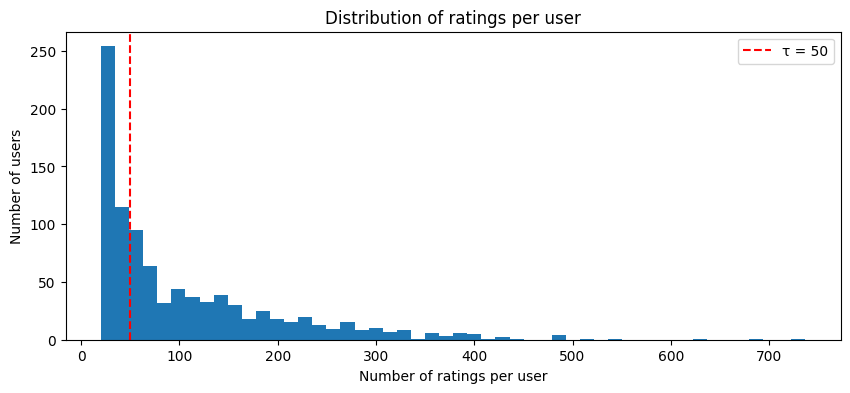

Users above τ=50: 568
Users below τ=50: 375
Median: 65
Mean:   106


In [101]:
# init the histogram
import matplotlib.pyplot as plt

train_matrix_full = dataPreprocessor(rating_df, num_users, num_items)
ratings_per_user = (train_matrix_full != 0).sum(axis=1)

tau = 50 
plt.figure(figsize=(10, 4))
plt.hist(ratings_per_user, bins=50)
plt.axvline(x=tau, color='red', linestyle='--', label=f'τ = {tau}')
plt.xlabel('Number of ratings per user')
plt.ylabel('Number of users')
plt.title('Distribution of ratings per user')
plt.legend()
plt.show()

print(f"Users above τ={tau}: {(ratings_per_user >= tau).sum()}")
print(f"Users below τ={tau}: {(ratings_per_user < tau).sum()}")

print(f"Median: {np.median(ratings_per_user):.0f}")
print(f"Mean:   {np.mean(ratings_per_user):.0f}")


### (a) ii)

In [102]:
cv_q6 = CrossValidation('RMSE')
algorithms_q6 = [user_cosine_recsys, item_cosine_recsys]

for label, above in [('Above τ', True), ('Below τ', False)]:
    scores = {alg.getPredColName(): [] for alg in algorithms_q6}
    
    for fold in cv_q6.folds:
        train_df, test_df = fold
        train_mat = dataPreprocessor(train_df, num_users, num_items)
        ratings_per_user_fold = (train_mat != 0).sum(axis=1)
        
        # user filtering (tau thresholding on train counts to avoid test data leakage)
        if above:
            selected_users = set(np.where(ratings_per_user_fold >= tau)[0] + 1)
        else:
            selected_users = set(np.where(ratings_per_user_fold < tau)[0] + 1)
        
        filtered_test = test_df[test_df.userID.isin(selected_users)]
        
        for alg in algorithms_q6:
            alg.reset()
            alg.predict_all(train_df, num_users, num_items)
            pred = alg.evaluate_test(filtered_test, copy=True)
            score = cv_q6.metric(pred, k=5, num_users=num_users, 
                                 num_items=num_items, pred=alg.getPredColName())
            scores[alg.getPredColName()].append(score)
    
    print(f"\n{label} (τ={tau}):")
    for name, fold_scores in scores.items():
        mean = np.mean(fold_scores)
        ci_lo, ci_hi = stats.t.interval(0.95, len(fold_scores)-1, 
                                         loc=mean, scale=stats.sem(fold_scores))
        print(f"  {name}: {mean:.4f} [{ci_lo:.4f}, {ci_hi:.4f}]")


15381it [00:00, 30479.77it/s]
15381it [00:00, 34823.91it/s]
16250it [00:00, 34262.81it/s]
16250it [00:00, 32438.82it/s]
16117it [00:00, 35019.22it/s]
16117it [00:00, 35109.52it/s]
16160it [00:00, 34753.44it/s]
16160it [00:00, 35185.36it/s]
14910it [00:00, 30161.30it/s]
14910it [00:00, 34917.23it/s]



Above τ (τ=50):
  user-cosine: 1.0144 [1.0058, 1.0230]
  item-cosine: 1.0152 [0.9985, 1.0318]


4619it [00:00, 33908.15it/s]
4619it [00:00, 35764.11it/s]
3750it [00:00, 34465.65it/s]
3750it [00:00, 35334.38it/s]
3883it [00:00, 34066.44it/s]
3883it [00:00, 34825.40it/s]
3840it [00:00, 34803.06it/s]
3840it [00:00, 34506.89it/s]
5090it [00:00, 35067.88it/s]
5090it [00:00, 34581.41it/s]


Below τ (τ=50):
  user-cosine: 1.0510 [1.0392, 1.0627]
  item-cosine: 1.0388 [1.0286, 1.0489]


Results:
Group	user-cosine RMSE	item-cosine RMSE
Above τ=50	1.0144	1.0152
Below τ=50	1.0510	1.0388

For this testing we choose τ = 50, separating users with few ratings (below) from those with moderate-to-many ratings (above). 

- **Above τ**: user-cosine (1.0144) and item-cosine (1.0152) performed almost identically and at their best. Active users have dense rating vectors, so their similarity to other users and items is computed reliably, leading to accurate predictions.

- **Below τ**: both methods degrade and the difference between them is notable: item-cosine (1.0388) outperforms user-cosine (1.0510). This makes sense, because a cold user with few ratings has a very sparse vector, making user-user similarity unreliable (not too many co-rated items to compare against other users).

**Conclusion**: User-user Colaborative Filtering is more sensitive to user sparsity than item-item CF. When users have few ratings, item-item CF is the safer choice.

# Validation

In [82]:
# Constants for validation only
ROW_NUM = 943
COL_NUM = 1682
RATING_COL = 'rating'

### dataPreprocessor

In [83]:
def validateDataPreprocessor(path=MOVIELENS_DIR, getData=getData, getMatrix=CrossValidation.getMatrix):
    validation_df = getData(MOVIELENS_DIR, 'u1.test')
    try:
        matrix = getMatrix(validation_df, ROW_NUM, COL_NUM, RATING_COL)
    except:
        print('dataPreprocessor function has error')
        return
    try:
        assert(matrix.shape == (ROW_NUM,COL_NUM)),\
        "Shape of matrix{0} doesn't match predefined shape (943,1682)".format(matrix.shape)
    except Exception as e:
        print(e)
    return validation_df

In [84]:
validation_df = validateDataPreprocessor()

## Baseline Recommendation Systems

### Popularity Based Recommendation

In [85]:
def validatePopularityRecSys(validation_df=validation_df, BaseLineRecSys = BaseLineRecSys):
    popularity_recsys = BaseLineRecSys('popularity')
    try:
        popularity_recsys.predict_all(validation_df, ROW_NUM, COL_NUM)
    except Exception as e:        
        print('popularity function has error')
        print(e)
        return
    try:
        predictionMatrix = popularity_recsys.getModel()
        assert(predictionMatrix.shape == (ROW_NUM, COL_NUM)),\
        "Shape of matrix{0} doesn't match predefined shape ({1},{2})"\
        .format(predictionMatrix.shape,ROW_NUM, COL_NUM)
    except Exception as e:
        print(e)

In [86]:
validatePopularityRecSys()

/var/folders/j5/vmwvb3vj1k18lnx4rzmv03pw0000gn/T/ipykernel_8996/3235414772.py:70: RuntimeWarning: invalid value encountered in divide
  item_popularity = np.where(rated_counts > 0, liked_counts / rated_counts, 0)


### User Average Based Recommendation

In [87]:
def validateUserAverRecSys(validation_df=validation_df, BaseLineRecSys = BaseLineRecSys):
    useraverage_recsys = BaseLineRecSys('average_user_rating')
    try:
        useraverage_recsys.predict_all(validation_df, ROW_NUM, COL_NUM)
    except:
        print('useraverage function has error')
        return
    try:
        predictionMatrix = useraverage_recsys.getModel()
        assert(predictionMatrix.shape == (ROW_NUM, COL_NUM)),\
        "Shape of matrix{0} doesn't match predefined shape ({1},{2})"\
        .format(predictionMatrix.shape,ROW_NUM, COL_NUM)
    except Exception as e:
        print(e)

In [88]:
validatePopularityRecSys()

/var/folders/j5/vmwvb3vj1k18lnx4rzmv03pw0000gn/T/ipykernel_8996/3235414772.py:70: RuntimeWarning: invalid value encountered in divide
  item_popularity = np.where(rated_counts > 0, liked_counts / rated_counts, 0)


## Similary Based Recommendation Systems

### Euclidean Similarity Function

In [89]:
def validateEuclidean(validation_df=validation_df, getMatrix=CrossValidation.getMatrix):
    matrix = getMatrix(validation_df, ROW_NUM, COL_NUM, RATING_COL)
    try:
        sim_matrix = SimBasedRecSys.euclidean(matrix)
        assert(sim_matrix.shape == (ROW_NUM, ROW_NUM)),\
        "Shape of matrix{0} doesn't match predefined shape ({1},{2})"\
        .format(sim_matrix.shape,ROW_NUM,ROW_NUM)
        assert(np.any(sim_matrix <= 1)),\
               "Exist similarity value that is not less or equal to 1."
    except Exception as e:
        print(e)        

In [90]:
validateEuclidean()

### Customized Similarity Function (test somethingelse function)

In [91]:
def validateCustomizedSim(validation_df=validation_df, getMatrix=CrossValidation.getMatrix):
    matrix = getMatrix(validation_df, ROW_NUM, COL_NUM, RATING_COL)
    try:
        sim_matrix = SimBasedRecSys.somethingelse(matrix)
        assert(sim_matrix.shape == (ROW_NUM, ROW_NUM)),\
        "Shape of matrix{0} doesn't match predefined shape ({1},{2})"\
        .format(sim_matrix.shape,ROW_NUM,ROW_NUM)
        assert(np.any(sim_matrix <= 1)),\
               "Exist similarity value that is not less or equal to 1."
    except Exception as e:
        print(e) 

In [92]:
validateCustomizedSim()

### User-User Similarity Based Recommendation System

In [93]:
def validateUUSimBasedRecSys(validation_df=validation_df, dataPreprocessor=dataPreprocessor):
    try:
        user_cosine_recsys = SimBasedRecSys('user','cosine', dataPreprocessor)
    except:
        print("Framework error, please make sure you are using given yml file.")
        return
    
    try:
        user_cosine_recsys.predict_all(validation_df, ROW_NUM, COL_NUM)
        predictionMatrix = user_cosine_recsys.getModel()
        assert(predictionMatrix.shape == (ROW_NUM, COL_NUM)),\
        "Shape of matrix{0} doesn't match predefined shape ({1},{2})"\
        .format(predictionMatrix.shape,ROW_NUM, COL_NUM)
    except Exception as e:
        print(e)

In [94]:
validateUUSimBasedRecSys()

### Item-Item Similarity Based Recommendation System

In [95]:
def validateIISimBasedRecSys(validation_df=validation_df, dataPreprocessor=dataPreprocessor):
    try:
        user_cosine_recsys = SimBasedRecSys('item','cosine', dataPreprocessor)
    except:
        print("Framework error, please make sure you are using given yml file.")
        return
    
    try:
        user_cosine_recsys.predict_all(validation_df, ROW_NUM, COL_NUM)
        predictionMatrix = user_cosine_recsys.getModel()
        assert(predictionMatrix.shape == (ROW_NUM, COL_NUM)),\
        "Shape of matrix{0} doesn't match predefined shape ({1},{2})"\
        .format(predictionMatrix.shape,ROW_NUM, COL_NUM)
    except Exception as e:
        print(e)

In [96]:
validateIISimBasedRecSys()